1. Data reading
   - load all 2024 months of taxi rides
   - also load taxi zone lookup data
   - include only rides starting in 2024 and ending at most at 01.01.2025
   - optimize data types, particularly for integers and categorical strings

In [50]:
import polars as pl

df_2024 = (
    pl.scan_parquet(
        "data/*.parquet",
        cast_options=pl.ScanCastOptions(datetime_cast="microsecond-upcast"),
    )
    .filter(
        (pl.col("tpep_pickup_datetime") >= pl.datetime(2024, 1, 1))
        & (pl.col("tpep_pickup_datetime") < pl.datetime(2025, 1, 1))
        & (pl.col("tpep_dropoff_datetime") <= pl.datetime(2025, 1, 1))
    )
    .with_columns(
        pl.col("tpep_pickup_datetime").dt.cast_time_unit("ms"),
        pl.col("tpep_dropoff_datetime").dt.cast_time_unit("ms"),
    )
)

In [51]:
df_2024 = df_2024.with_columns(
    pl.col("VendorID").cast(pl.UInt8),
    pl.col("passenger_count").cast(pl.UInt8),
    pl.col("RatecodeID").cast(pl.UInt8),
    pl.col("PULocationID").cast(pl.UInt16),
    pl.col("DOLocationID").cast(pl.UInt16),
    pl.col("payment_type").cast(pl.UInt8),
    pl.col("store_and_fwd_flag").cast(pl.Categorical),
)

In [52]:
df_taxi_zones = pl.scan_csv("data/taxi_zone_lookup.csv")

In [53]:
amount_cols = [
    "fare_amount",
    "extra",
    "mta_tax",
    "tip_amount",
    "tolls_amount",
    "improvement_surcharge",
    "total_amount",
    "congestion_surcharge",
    "Airport_fee",
]
correct_ratecode_ids = [1, 2, 3, 4, 5, 6, 99]
correct_vendor_ids = [1, 2, 6, 7]
df_2024 = (
    df_2024.filter(
        (
            pl.col("tpep_dropoff_datetime") - pl.col("tpep_pickup_datetime")
        ).dt.total_minutes()
        <= 120
    )
    .with_columns(
        pl.col("passenger_count").fill_null(1).replace({i: 6 for i in range(7, 10)})
    )
    .filter(pl.col("passenger_count") != 0)
    .with_columns(pl.col(amount_cols).abs())
    .filter(~pl.any_horizontal(pl.col(amount_cols) > 1000))
    .filter(pl.col("VendorID").is_in(correct_vendor_ids))
    .filter(pl.col("RatecodeID").is_in(correct_ratecode_ids))
)

In [54]:
df_2024 = df_2024.with_columns(
    pl.col("payment_type").replace({i: 0 for i in [3, 4, 5, 6]})
)

df_2024 = (
    df_2024.join(
        df_taxi_zones.select(["LocationID", pl.col("Borough").alias("pickup_borough")]),
        left_on="PULocationID",
        right_on="LocationID",
    )
    .join(
        df_taxi_zones.select(
            ["LocationID", pl.col("Borough").alias("dropoff_borough")]
        ),
        left_on="DOLocationID",
        right_on="LocationID",
    )
    .drop(["PULocationID", "DOLocationID"])
)

In [55]:
df_2024 = df_2024.with_columns(
    (pl.col("Airport_fee").fill_null(0) != 0).alias("is_airport_ride")
)

In [56]:
from datetime import time

df_2024 = df_2024.with_columns(
    (
        (pl.col("tpep_pickup_datetime").dt.weekday() <= 5)
        & (
            pl.col("tpep_pickup_datetime")
            .dt.time()
            .is_between(time(6, 30), time(9, 30))
            | pl.col("tpep_pickup_datetime")
            .dt.time()
            .is_between(time(15, 30), time(20, 0))
        )
    )
    .fill_null(False)
    .alias("is_rush_hour")
)

In [57]:
df_2024 = df_2024.with_columns(
    (pl.col("payment_type") == 1).cast(pl.UInt8).alias("payment_card"),
    (pl.col("payment_type") == 2).cast(pl.UInt8).alias("payment_cash"),
    (pl.col("payment_type") == 0).cast(pl.UInt8).alias("payment_other"),
)

In [58]:
boroughs = (
    df_taxi_zones.select("Borough")
    .unique()
    .collect()
    .get_column("Borough")
    .drop_nulls()
    .to_list()
)

In [59]:
df_2024 = df_2024.with_columns(
    [
        (pl.col(column) == borough)
        .fill_null(False)
        .cast(pl.UInt8)
        .alias(f"{column}_{borough.lower().replace(' ', '_')}")
        for column in ["pickup_borough", "dropoff_borough"]
        for borough in boroughs
    ]
)

In [60]:
payment_types = {
    0: "other",
    1: "card",
    2: "cash",
}

df_2024_daily = (
    df_2024.with_columns(pl.col("tpep_pickup_datetime").dt.date().alias("date"))
    .group_by("date")
    .agg(
        pl.len().alias("total_rides"),
        pl.col("is_airport_ride").sum().alias("airport_rides"),
        pl.col("is_rush_hour").sum().alias("rush_hour_rides"),
        pl.col("fare_amount").mean().alias("average_fare_amount"),
        pl.col("trip_distance").median().alias("median_trip_distance"),
        pl.col("total_amount").sum().alias("total_amount_sum"),
        *[
            pl.col("total_amount")
            .filter(pl.col("payment_type") == code)
            .sum()
            .alias(f"total_amount_{name}")
            for code, name in payment_types.items()
        ],
        pl.col("congestion_surcharge").sum().alias("congestion_surcharge_sum"),
        pl.col("passenger_count").sum().alias("passenger_count_sum"),
        *[
            pl.col(f"{column}_{borough.lower().replace(' ', '_')}")
            .sum()
            .alias(f"{column}_{borough.lower().replace(' ', '_')}_rides")
            for column in ["pickup_borough", "dropoff_borough"]
            for borough in boroughs
        ],
        *[
            (pl.col("payment_type") == code).sum().alias(f"payment_{name}_rides")
            for code, name in payment_types.items()
        ],
    )
    .with_columns(
        pl.col("date").dt.quarter().alias("quarter"),
        pl.col("date").dt.month().alias("month"),
        pl.col("date").dt.days_in_month().alias("day_of_month"),
        (~pl.col("date").dt.is_business_day()).alias("is_weekend"),
    )
)

In [61]:
df_2024_daily.head(6).collect()

date,total_rides,airport_rides,rush_hour_rides,average_fare_amount,median_trip_distance,total_amount_sum,total_amount_other,total_amount_card,total_amount_cash,congestion_surcharge_sum,passenger_count_sum,pickup_borough_manhattan_rides,pickup_borough_ewr_rides,pickup_borough_bronx_rides,pickup_borough_n/a_rides,pickup_borough_unknown_rides,pickup_borough_staten_island_rides,pickup_borough_brooklyn_rides,pickup_borough_queens_rides,dropoff_borough_manhattan_rides,dropoff_borough_ewr_rides,dropoff_borough_bronx_rides,dropoff_borough_n/a_rides,dropoff_borough_unknown_rides,dropoff_borough_staten_island_rides,dropoff_borough_brooklyn_rides,dropoff_borough_queens_rides,payment_other_rides,payment_card_rides,payment_cash_rides,quarter,month,day_of_month,is_weekend
date,u32,u32,u32,f64,f64,f64,f64,f64,f64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,u32,u32,u32,i8,i8,i8,bool
2024-03-20,106121,8360,44924,19.149939,1.69,3.0300e6,63296.31,2.6017e6,364914.83,245295.0,135691,95087,14,269,59,336,1,873,9482,94889,322,584,410,544,31,3813,5528,2449,88573,15099,1,3,31,false
2024-04-19,108203,8275,42506,19.125929,1.68,3.0748e6,68294.81,2.6090e6,397434.08,250387.5,146597,97235,12,281,44,346,1,983,9301,97055,341,639,382,528,19,4066,5173,2782,89129,16292,2,4,30,false
2024-04-01,85754,10051,35931,20.365614,1.8,2.5667e6,61123.81,2.1433e6,362248.46,193802.5,117075,73133,11,208,45,302,1,894,11160,75603,240,642,428,428,35,3468,4910,2276,69205,14273,2,4,30,false
2024-12-10,126222,10328,51232,20.818467,1.6,3.8603e6,89638.98,3.3677e6,403013.65,294258.25,159734,113100,15,261,65,336,6,1070,11369,113960,290,596,608,459,37,4636,5636,3274,107268,15680,4,12,31,false
2024-03-14,118048,8917,48976,19.63615,1.72,3.4335e6,70224.37,2.9378e6,425515.99,275137.5,153586,106240,14,242,67,380,0,1032,10073,105749,318,677,461,576,19,4565,5683,2776,98268,17004,1,3,31,false
2024-03-26,99090,8817,41648,19.398869,1.71,2.8446e6,66067.58,2.4041e6,374414.76,227737.5,130239,87527,11,263,63,309,2,959,9956,88557,183,600,416,456,26,3928,4924,2452,81530,15108,1,3,31,false


In [62]:
df_2024_daily.sink_parquet("dataset.parquet")

In [63]:
import polars as pl

daily = pl.read_parquet("dataset.parquet").sort("date")

In [64]:
print("Shape:", daily.shape)

Shape: (366, 35)


In [65]:
daily.head()

date,total_rides,airport_rides,rush_hour_rides,average_fare_amount,median_trip_distance,total_amount_sum,total_amount_other,total_amount_card,total_amount_cash,congestion_surcharge_sum,passenger_count_sum,pickup_borough_manhattan_rides,pickup_borough_ewr_rides,pickup_borough_bronx_rides,pickup_borough_n/a_rides,pickup_borough_unknown_rides,pickup_borough_staten_island_rides,pickup_borough_brooklyn_rides,pickup_borough_queens_rides,dropoff_borough_manhattan_rides,dropoff_borough_ewr_rides,dropoff_borough_bronx_rides,dropoff_borough_n/a_rides,dropoff_borough_unknown_rides,dropoff_borough_staten_island_rides,dropoff_borough_brooklyn_rides,dropoff_borough_queens_rides,payment_other_rides,payment_card_rides,payment_cash_rides,quarter,month,day_of_month,is_weekend
date,u32,u32,u32,f64,f64,f64,f64,f64,f64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,u32,u32,u32,i8,i8,i8,bool
2024-01-01,69665,8352,19398,22.217628,2.09,2.1849e6,55778.86,1.7445e6,384662.67,156123.25,109137,59261,21,82,93,271,3,664,9270,58606,388,583,605,444,31,3825,5183,2204,52970,14491,1,1,31,false
2024-01-02,72585,9828,31015,21.506212,1.82,2.2505e6,51441.03,1.8023e6,396698.77,160617.5,104073,60494,20,167,54,266,2,685,10897,62613,319,555,438,385,32,3411,4832,2022,55175,15388,1,1,31,false
2024-01-03,79566,9140,33389,20.170854,1.75,2.3320e6,49554.25,1.8662e6,416241.57,177985.0,110973,68074,16,228,36,315,1,679,10217,69706,282,640,398,473,14,3464,4589,2021,61343,16202,1,1,31,false
2024-01-04,99077,8270,43572,18.866102,1.75,2760359.9,59823.2,2.2559e6,444631.77,226627.5,135815,88459,10,244,40,385,1,666,9272,89107,226,757,346,549,14,3463,4615,2345,78738,17994,1,1,31,false
2024-01-05,98860,7460,40518,18.246814,1.7,2.6767e6,57798.23,2.1982e6,420698.52,227542.5,137166,89232,8,183,37,394,1,606,8399,89459,222,651,345,608,20,3182,4373,2460,78701,17699,1,1,31,false


In [66]:
daily.describe()

statistic,date,total_rides,airport_rides,rush_hour_rides,average_fare_amount,median_trip_distance,total_amount_sum,total_amount_other,total_amount_card,total_amount_cash,congestion_surcharge_sum,passenger_count_sum,pickup_borough_manhattan_rides,pickup_borough_ewr_rides,pickup_borough_bronx_rides,pickup_borough_n/a_rides,pickup_borough_unknown_rides,pickup_borough_staten_island_rides,pickup_borough_brooklyn_rides,pickup_borough_queens_rides,dropoff_borough_manhattan_rides,dropoff_borough_ewr_rides,dropoff_borough_bronx_rides,dropoff_borough_n/a_rides,dropoff_borough_unknown_rides,dropoff_borough_staten_island_rides,dropoff_borough_brooklyn_rides,dropoff_borough_queens_rides,payment_other_rides,payment_card_rides,payment_cash_rides,quarter,month,day_of_month,is_weekend
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""366""",366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0
"""null_count""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""","""2024-07-01 12:00:00""",100098.625683,8978.631148,29943.382514,19.953609,1.718648,2.9113e6,78165.862732,2.4609e6,372267.261585,230205.821093,134962.710383,88510.650273,15.983607,206.300546,60.185792,312.636612,2.579235,882.521858,10107.76776,89043.221311,284.546448,590.237705,484.822404,448.904372,25.256831,4009.098361,5212.538251,2932.008197,82242.849727,14923.76776,2.505464,6.513661,30.513661,0.284153
"""std""",null,15373.530846,1716.749204,19695.067511,1.204952,0.100899,461652.281739,17271.236728,428958.667174,36204.401117,37866.165971,18726.35811,15154.656105,7.71263,51.234859,18.122216,57.292106,1.735371,202.013707,1765.357262,14678.507546,73.626133,68.000812,93.834881,92.056708,6.761263,581.957016,689.388442,554.320818,14162.236556,1357.284716,1.119551,3.455958,0.639845,null
"""min""","""2024-01-01""",47391.0,3355.0,0.0,16.676264,1.5,1.3260e6,41303.84,996577.34,240633.43,107825.0,74199.0,41757.0,2.0,48.0,23.0,149.0,0.0,298.0,4935.0,41657.0,122.0,370.0,261.0,192.0,9.0,1831.0,2827.0,1656.0,34052.0,10244.0,1.0,1.0,29.0,0.0
"""25%""","""2024-04-01""",89573.0,7869.0,0.0,19.125929,1.66,2.5818e6,65781.9,2.1702e6,352429.45,203501.0,122222.0,77350.0,10.0,166.0,46.0,273.0,1.0,731.0,8862.0,78535.0,236.0,545.0,418.0,390.0,20.0,3682.0,4773.0,2566.0,72543.0,14109.0,2.0,4.0,30.0,null
"""50%""","""2024-07-02""",100782.0,9020.0,39519.0,19.953055,1.7,2.9166e6,79217.11,2.4630e6,375977.94,232825.0,134084.0,89891.0,15.0,216.0,59.0,310.0,2.0,938.0,10073.0,90293.0,275.0,591.0,481.0,444.0,25.0,4009.0,5252.0,2910.0,83419.0,14966.0,3.0,7.0,31.0,null
"""75%""","""2024-10-01""",110805.0,10144.0,44785.0,20.713722,1.77,3.2229e6,90279.69,2.7451e6,398649.5,256942.0,147190.0,99602.0,20.0,243.0,70.0,347.0,3.0,1019.0,11254.0,99447.0,335.0,639.0,549.0,515.0,30.0,4378.0,5703.0,3271.0,91739.0,15835.0,4.0,10.0,31.0,null
"""max""","""2024-12-31""",141702.0,14904.0,56582.0,24.447593,2.2,4.4645e6,123894.72,3.9183e6,449948.51,330475.0,199442.0,128161.0,47.0,324.0,125.0,505.0,8.0,1674.0,16177.0,127687.0,583.0,801.0,716.0,718.0,51.0,6237.0,6851.0,4596.0,120997.0,17994.0,4.0,12.0,31.0,1.0


In [67]:
daily.schema

Schema([('date', Date),
        ('total_rides', UInt32),
        ('airport_rides', UInt32),
        ('rush_hour_rides', UInt32),
        ('average_fare_amount', Float64),
        ('median_trip_distance', Float64),
        ('total_amount_sum', Float64),
        ('total_amount_other', Float64),
        ('total_amount_card', Float64),
        ('total_amount_cash', Float64),
        ('congestion_surcharge_sum', Float64),
        ('passenger_count_sum', Int64),
        ('pickup_borough_manhattan_rides', Int64),
        ('pickup_borough_ewr_rides', Int64),
        ('pickup_borough_bronx_rides', Int64),
        ('pickup_borough_n/a_rides', Int64),
        ('pickup_borough_unknown_rides', Int64),
        ('pickup_borough_staten_island_rides', Int64),
        ('pickup_borough_brooklyn_rides', Int64),
        ('pickup_borough_queens_rides', Int64),
        ('dropoff_borough_manhattan_rides', Int64),
        ('dropoff_borough_ewr_rides', Int64),
        ('dropoff_borough_bronx_rides', Int64),
   

<Axes: title={'center': 'Distribution of Daily Taxi Rides in 2024'}, xlabel='Daily Number of Rides', ylabel='Number of Days'>

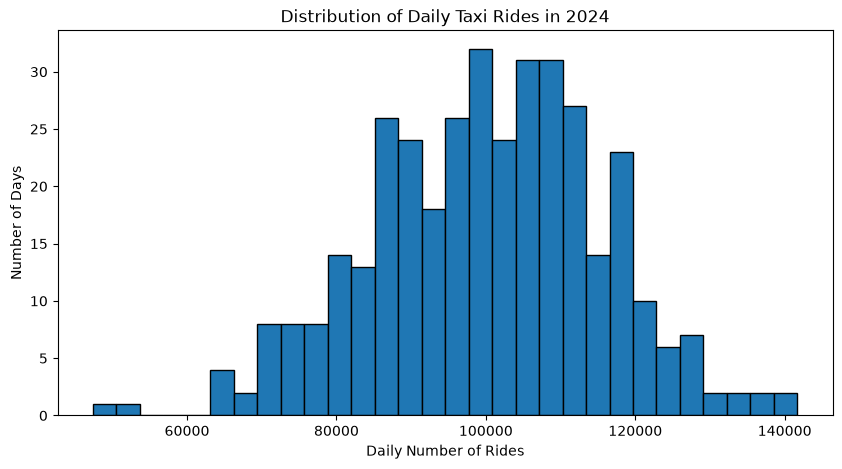

In [68]:
daily.to_pandas().sort_values("date")["total_rides"].plot.hist(
    bins=30,
    edgecolor="black",
    figsize=(10, 5),
    title="Distribution of Daily Taxi Rides in 2024",
    xlabel="Daily Number of Rides",
    ylabel="Number of Days",
)

<Axes: title={'center': 'Daily Taxi Rides in 2024'}, xlabel='Date', ylabel='Number of Rides'>

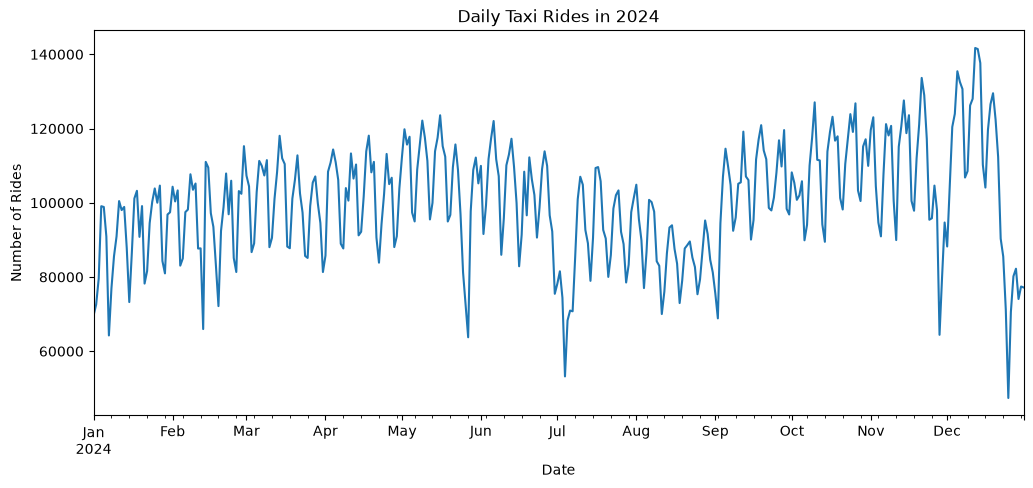

In [69]:
daily.to_pandas().sort_values("date").plot(
    x="date",
    y="total_rides",
    figsize=(12, 5),
    title="Daily Taxi Rides in 2024",
    xlabel="Date",
    ylabel="Number of Rides",
    legend=False,
)